In [1]:
# ============================================================
# Predicción de abandono de clientes — IBM Telco Customer Churn
# Documentación completa: DOCUMENTACION.md
# Kernel: Python 3.15 (Telco Churn)
# ============================================================

# 1. Configuración e importaciones
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Reproducibilidad y rutas
RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20
DATA_PATH = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
TARGET = "Churn"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

print(f"Python      : {sys.version.split()[0]}")
print(f"pandas      : {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"XGBoost     : {xgboost.__version__}")

Python      : 3.15.2
pandas      : 3.1.1
scikit-learn: 1.9.1
XGBoost     : 3.4.1


In [2]:
# 2. Carga y revisión inicial
df = pd.read_csv(DATA_PATH)

print(f"Registros: {df.shape[0]:,} | Columnas: {df.shape[1]}")
print(f"Clientes únicos: {df['customerID'].nunique():,}")
df.head()

Registros: 7,043 | Columnas: 21
Clientes únicos: 7,043


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [3]:
# Tipos, nulos y cardinalidad de cada variable
resumen = pd.DataFrame(
    {
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    }
)
resumen

,tipo,nulos,valores_unicos,ejemplo
customerID,str,0,7043,7590-VHVEG
gender,str,0,2,Female
SeniorCitizen,int64,0,2,0
Partner,str,0,2,Yes
Dependents,str,0,2,No
tenure,int64,0,73,1
PhoneService,str,0,2,No
MultipleLines,str,0,3,No phone service
InternetService,str,0,3,DSL
OnlineSecurity,str,0,3,No


In [4]:
# Distribución del objetivo: 26,54 % de abandono
conteo = df[TARGET].value_counts().rename(index={"No": "No abandona", "Yes": "Abandona"})
tabla_objetivo = pd.DataFrame(
    {
        "clientes": conteo,
        "porcentaje": (conteo / len(df) * 100).round(2),
    }
)
print(tabla_objetivo.to_string())

# TotalCharges llega como texto por 11 espacios en blanco
print("\nValores no numéricos en TotalCharges:")
no_numericos = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print(f"  {no_numericos.sum()} registros")
print(df.loc[no_numericos, ["tenure", "MonthlyCharges", "TotalCharges"]].to_string(index=False))

             clientes  porcentaje
Churn                            
No abandona      5174      73.460
Abandona         1869      26.540

Valores no numéricos en TotalCharges:
  11 registros
 tenure  MonthlyCharges TotalCharges
      0          52.550             
      0          20.250             
      0          80.850             
      0          25.750             
      0          56.050             
      0          19.850             
      0          25.350             
      0          20.000             
      0          19.700             
      0          73.350             
      0          61.900             


In [5]:
# 3. Depuración
# Regla de negocio: TotalCharges solo puede faltar en clientes con tenure = 0.
# Si aparece otro caso, el proceso se detiene para revisarlo.
df = df.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})

assert df["customerID"].is_unique, "Hay identificadores duplicados"
assert df[TARGET].notna().all(), "La variable objetivo contiene valores no reconocidos"

faltantes = df["TotalCharges"].isna()
assert (df.loc[faltantes, "tenure"] == 0).all(), (
    "Hay TotalCharges faltantes con tenure > 0: revisar antes de imputar"
)

print(f"TotalCharges faltante: {faltantes.sum()} casos, todos con tenure = 0")
print(f"Tasa de abandono: {df[TARGET].mean():.2%}")

TotalCharges faltante: 11 casos, todos con tenure = 0
Tasa de abandono: 26.54%


In [6]:
# 4. Partición 60/20/20
# - entrenamiento: ajuste de hiperparámetros
# - validación: selección del modelo y del umbral
# - prueba: evaluación final, una sola vez
X = df.drop(columns=["customerID", TARGET])
y = df[TARGET]

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=VALIDATION_SIZE / (1 - TEST_SIZE),
    stratify=y_dev,
    random_state=RANDOM_STATE,
)

print(f"Entrenamiento: {X_train.shape[0]:,} | abandono {y_train.mean():.2%}")
print(f"Validación   : {X_val.shape[0]:,} | abandono {y_val.mean():.2%}")
print(f"Prueba       : {X_test.shape[0]:,} | abandono {y_test.mean():.2%}")

Entrenamiento: 4,225 | abandono 26.53%
Validación   : 1,409 | abandono 26.54%
Prueba       : 1,409 | abandono 26.54%


In [7]:
# 5. Análisis exploratorio (solo entrenamiento)
# Se comparan tasas, no conteos: un segmento grande puede tener más casos sin mayor riesgo.
train = X_train.assign(Churn=y_train)


def tasa_por(columna):
    tabla = (
        train.groupby(columna, observed=True)["Churn"]
        .agg(clientes="size", tasa="mean")
        .sort_values("tasa", ascending=False)
    )
    tabla["tasa"] = (tabla["tasa"] * 100).round(1)
    return tabla


for variable in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    print(f"\nTasa de abandono por {variable} (%):")
    print(tasa_por(variable).to_string())


Tasa de abandono por Contract (%):
                clientes   tasa
Contract                       
Month-to-month      2326 43.100
One year             865 10.800
Two year            1034  2.500

Tasa de abandono por InternetService (%):
                 clientes   tasa
InternetService                 
Fiber optic          1843 42.300
DSL                  1474 18.700
No                    908  7.300

Tasa de abandono por PaymentMethod (%):
                           clientes   tasa
PaymentMethod                             
Electronic check               1410 45.600
Mailed check                    980 19.500
Bank transfer (automatic)       926 16.200
Credit card (automatic)         909 15.100

Tasa de abandono por TechSupport (%):
                     clientes   tasa
TechSupport                         
No                       2082 41.800
Yes                      1235 15.000
No internet service       908  7.300


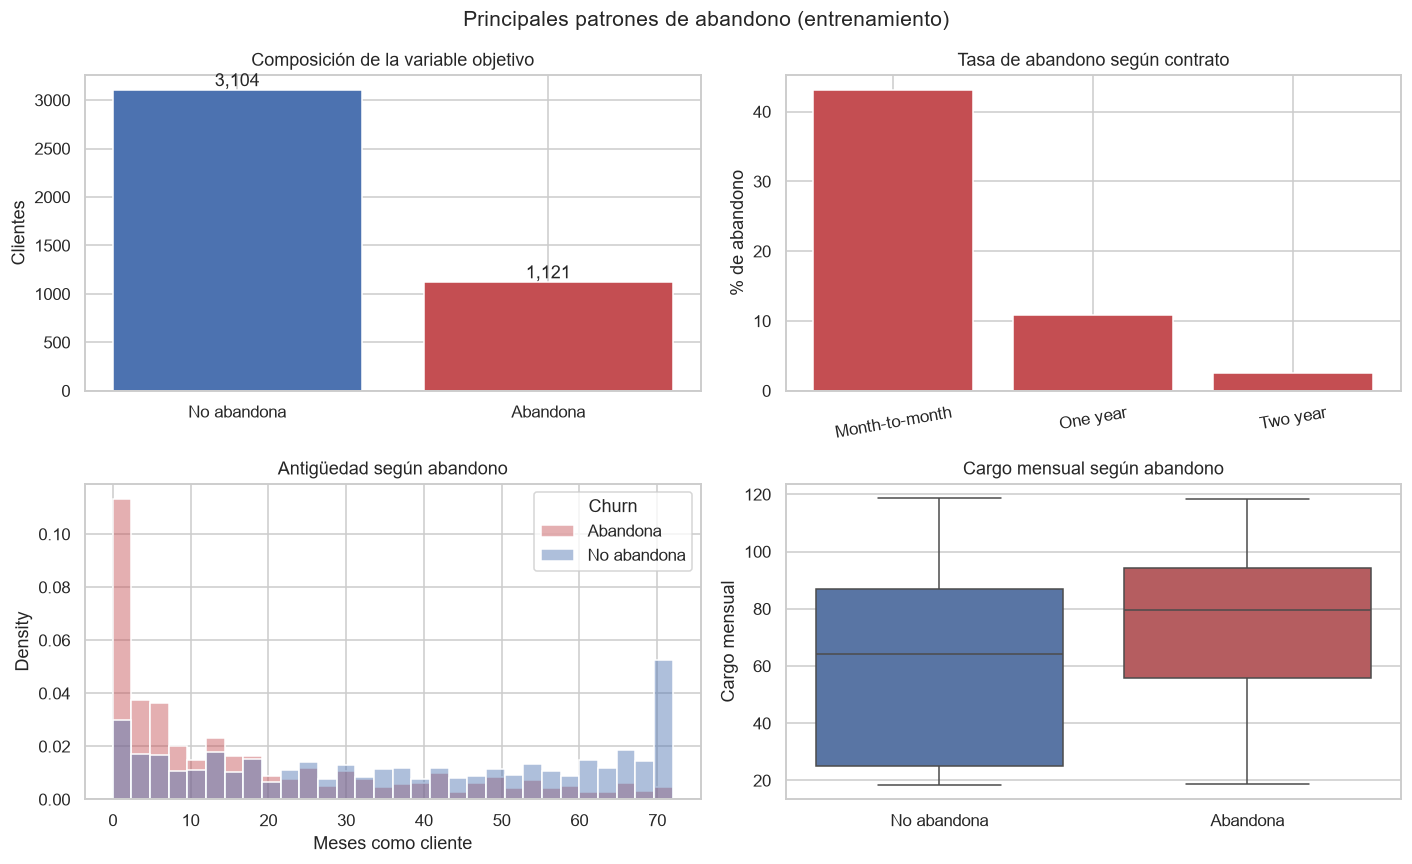

In [8]:
# Figura 1: objetivo, contrato, antigüedad y cargo mensual
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

conteo = train["Churn"].map({0: "No abandona", 1: "Abandona"}).value_counts()
axes[0, 0].bar(conteo.index, conteo.values, color=["#4C72B0", "#C44E52"])
axes[0, 0].set_title("Composición de la variable objetivo")
axes[0, 0].set_ylabel("Clientes")
for i, valor in enumerate(conteo.values):
    axes[0, 0].text(i, valor, f"{valor:,}", ha="center", va="bottom")

tasa_contrato = tasa_por("Contract")
axes[0, 1].bar(tasa_contrato.index, tasa_contrato["tasa"], color="#C44E52")
axes[0, 1].set_title("Tasa de abandono según contrato")
axes[0, 1].set_ylabel("% de abandono")
axes[0, 1].tick_params(axis="x", rotation=10)

sns.histplot(
    data=train,
    x="tenure",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    palette={0: "#4C72B0", 1: "#C44E52"},
    alpha=0.45,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Antigüedad según abandono")
axes[1, 0].set_xlabel("Meses como cliente")
axes[1, 0].legend(title="Churn", labels=["Abandona", "No abandona"])

sns.boxplot(
    data=train,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette={0: "#4C72B0", 1: "#C44E52"},
    legend=False,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Cargo mensual según abandono")
axes[1, 1].set_xlabel("")
axes[1, 1].set_xticks([0, 1], ["No abandona", "Abandona"])
axes[1, 1].set_ylabel("Cargo mensual")

fig.suptitle("Principales patrones de abandono (entrenamiento)", fontsize=14)
fig.tight_layout()
plt.show()

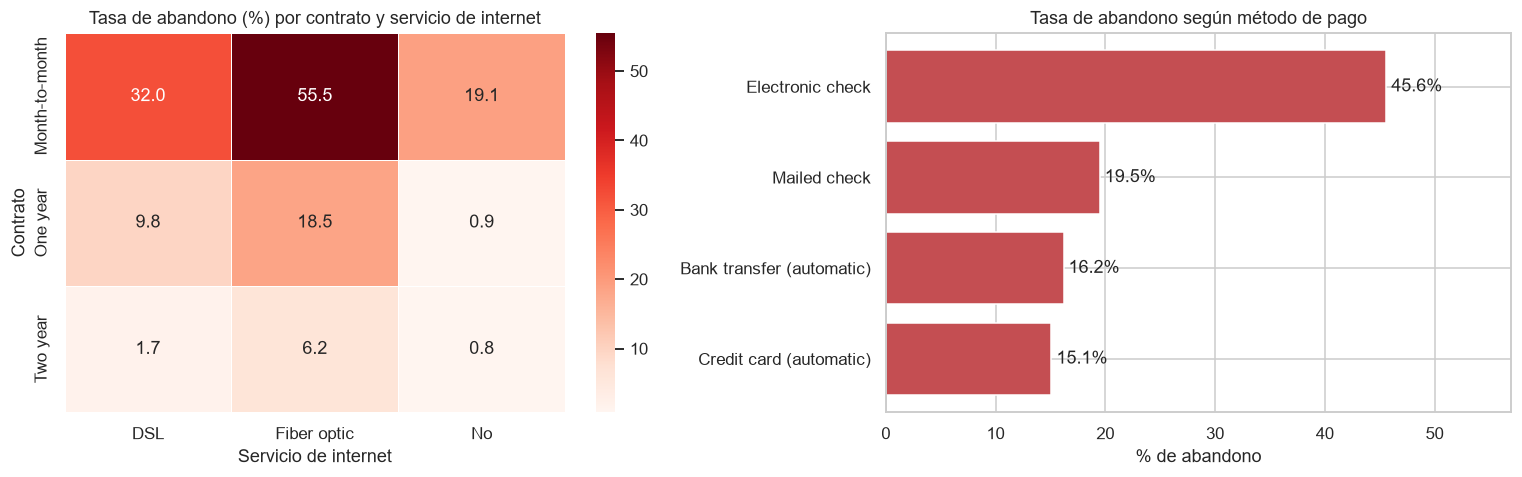

In [9]:
# Figura 2: contrato x internet y método de pago
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pivote = (
    train.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="mean")
    * 100
)
sns.heatmap(pivote, annot=True, fmt=".1f", cmap="Reds", linewidths=0.5, ax=axes[0])
axes[0].set_title("Tasa de abandono (%) por contrato y servicio de internet")
axes[0].set_xlabel("Servicio de internet")
axes[0].set_ylabel("Contrato")

tasa_pago = tasa_por("PaymentMethod")
axes[1].barh(tasa_pago.index[::-1], tasa_pago["tasa"][::-1], color="#C44E52")
axes[1].set_title("Tasa de abandono según método de pago")
axes[1].set_xlabel("% de abandono")
axes[1].set_xlim(0, max(tasa_pago["tasa"]) * 1.25)
for i, valor in enumerate(tasa_pago["tasa"][::-1]):
    axes[1].text(valor, i, f" {valor:.1f}%", va="center")

fig.tight_layout()
plt.show()

In [10]:
# 6. Preparación de variables
# Todo se aprende dentro del pipeline y de cada partición de validación cruzada.
NUMERICAS_MEDIANA = ["tenure", "MonthlyCharges"]
NUMERICAS_CERO = ["TotalCharges"]
CATEGORICAS = [
    columna
    for columna in X_train.columns
    if columna not in NUMERICAS_MEDIANA + NUMERICAS_CERO
]

rama_mediana = Pipeline(
    [
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ]
)

# TotalCharges faltante = cliente nuevo sin facturación acumulada
rama_cero = Pipeline(
    [
        ("imputar", SimpleImputer(strategy="constant", fill_value=0)),
        ("escalar", StandardScaler()),
    ]
)

rama_categorica = Pipeline(
    [
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocesador = ColumnTransformer(
    [
        ("num_mediana", rama_mediana, NUMERICAS_MEDIANA),
        ("num_cero", rama_cero, NUMERICAS_CERO),
        ("cat", rama_categorica, CATEGORICAS),
    ]
)

print(f"Variables numéricas (mediana): {NUMERICAS_MEDIANA}")
print(f"Variables numéricas (cero)   : {NUMERICAS_CERO}")
print(f"Variables categóricas        : {len(CATEGORICAS)}")
print(", ".join(CATEGORICAS))

Variables numéricas (mediana): ['tenure', 'MonthlyCharges']
Variables numéricas (cero)   : ['TotalCharges']
Variables categóricas        : 16
gender, SeniorCitizen, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod


In [11]:
# 7. Modelos y grillas de hiperparámetros
# class_weight / scale_pos_weight dan más peso a la clase minoritaria.
MODELOS = {
    "Regresión logística": {
        "estimador": LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "grilla": {"clf__C": [0.1, 1.0, 10.0]},
    },
    "KNN": {
        "estimador": KNeighborsClassifier(),
        "grilla": {
            "clf__n_neighbors": [5, 15, 31],
            "clf__weights": ["uniform", "distance"],
        },
    },
    "Árbol de decisión": {
        "estimador": DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "grilla": {
            "clf__max_depth": [3, 5, 7],
            "clf__min_samples_leaf": [5, 20],
        },
    },
    "Random Forest": {
        "estimador": RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        "grilla": {
            "clf__max_depth": [None, 8],
            "clf__min_samples_leaf": [1, 5],
        },
    },
    "XGBoost": {
        "estimador": XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=float((y_train == 0).sum() / (y_train == 1).sum()),
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        "grilla": {
            "clf__max_depth": [3, 5],
            "clf__learning_rate": [0.05, 0.1],
        },
    },
}

print("Modelos configurados:")
for nombre in MODELOS:
    print(f"  - {nombre}")

Modelos configurados:
  - Regresión logística
  - KNN
  - Árbol de decisión
  - Random Forest
  - XGBoost


In [12]:
# 8. Línea base trivial
# "Siempre no abandona" alcanza ~73,5 % de accuracy con recall 0:
# demuestra por qué la accuracy no sirve como métrica principal.
METRICAS = {
    "average_precision": "Average precision",
    "roc_auc": "ROC-AUC",
    "recall": "Recall",
    "precision": "Precision",
    "f1": "F1",
    "accuracy": "Accuracy",
}

SCORING = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "accuracy": "accuracy",
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = DummyClassifier(strategy="most_frequent")
cv_baseline = cross_validate(baseline, X_train, y_train, cv=cv, scoring=SCORING)

tabla_baseline = pd.DataFrame(
    {
        etiqueta: f"{cv_baseline[f'test_{metrica}'].mean():.3f} ± "
        f"{cv_baseline[f'test_{metrica}'].std():.3f}"
        for metrica, etiqueta in METRICAS.items()
    },
    index=["Siempre 'no abandona'"],
).T

tabla_baseline.columns = ["Resultado"]
tabla_baseline

,Resultado
Average precision,0.265 ± 0.000
ROC-AUC,0.500 ± 0.000
Recall,0.000 ± 0.000
Precision,0.000 ± 0.000
F1,0.000 ± 0.000
Accuracy,0.735 ± 0.000


In [13]:
# 9. Ajuste de hiperparámetros (solo entrenamiento)
# GridSearchCV con validación cruzada estratificada; se selecciona por average precision.
resultados_ajuste = {}

for nombre, configuracion in MODELOS.items():
    pipeline = Pipeline(
        [
            ("preprocesador", preprocesador),
            ("clf", configuracion["estimador"]),
        ]
    )
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=configuracion["grilla"],
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=-1,
    )

    inicio = time.perf_counter()
    busqueda.fit(X_train, y_train)
    duracion = time.perf_counter() - inicio

    resultados_ajuste[nombre] = {
        "busqueda": busqueda,
        "mejores_parametros": busqueda.best_params_,
        "ap_validacion_cruzada": busqueda.best_score_,
        "segundos": duracion,
    }

    parametros = ", ".join(
        f"{clave.replace('clf__', '')}={valor}"
        for clave, valor in busqueda.best_params_.items()
    )
    print(
        f"{nombre:<22} AP={busqueda.best_score_:.4f} | "
        f"{duracion:6.1f} s | {parametros}"
    )

Regresión logística    AP=0.6653 |    7.5 s | C=10.0


KNN                    AP=0.6227 |    2.3 s | n_neighbors=31, weights=uniform


Árbol de decisión      AP=0.6173 |    1.5 s | max_depth=7, min_samples_leaf=20


Random Forest          AP=0.6698 |   13.6 s | max_depth=8, min_samples_leaf=5


XGBoost                AP=0.6704 |    6.3 s | learning_rate=0.05, max_depth=3


In [14]:
# 9.1 Comparación en validación y selección del modelo
# El conjunto de prueba no participa en esta decisión.
mejores_modelos = {
    nombre: resultado["busqueda"].best_estimator_
    for nombre, resultado in resultados_ajuste.items()
}

probabilidades_val = {}
filas = []

for nombre, modelo in mejores_modelos.items():
    probabilidad = modelo.predict_proba(X_val)[:, 1]
    probabilidades_val[nombre] = probabilidad
    prediccion = (probabilidad >= 0.5).astype(int)

    filas.append(
        {
            "Modelo": nombre,
            "Average precision": average_precision_score(y_val, probabilidad),
            "ROC-AUC": roc_auc_score(y_val, probabilidad),
            "Recall @0,5": recall_score(y_val, prediccion),
            "Precision @0,5": precision_score(y_val, prediccion),
            "F1 @0,5": f1_score(y_val, prediccion),
            "Accuracy @0,5": accuracy_score(y_val, prediccion),
        }
    )

tabla_validacion = (
    pd.DataFrame(filas)
    .set_index("Modelo")
    .sort_values("Average precision", ascending=False)
)
tabla_validacion.insert(0, "Puesto", range(1, len(tabla_validacion) + 1))

modelo_seleccionado = tabla_validacion.index[0]
print(f"Modelo seleccionado por AP de validación: {modelo_seleccionado}")
tabla_validacion.round(3)

Modelo seleccionado por AP de validación: XGBoost


,Puesto,Average precision,ROC-AUC,"Recall @0,5","Precision @0,5","F1 @0,5","Accuracy @0,5"
Modelo,,,,,,,
XGBoost,1,0.648,0.838,0.765,0.517,0.617,0.748
Regresión logística,2,0.643,0.837,0.786,0.512,0.620,0.744
Random Forest,3,0.638,0.838,0.786,0.510,0.619,0.743
Árbol de decisión,4,0.601,0.818,0.773,0.495,0.603,0.730
KNN,5,0.595,0.824,0.561,0.621,0.590,0.793


In [15]:
# 10. Ajuste del umbral sobre validación
# Se maximiza F1 en validación; el conjunto de prueba no participa.
umbrales = {}
resumen_umbral = []

for nombre, probabilidad in probabilidades_val.items():
    precision, recall, candidatos = precision_recall_curve(y_val, probabilidad)
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) > 0,
    )
    indice = int(np.argmax(f1[:-1]))
    umbral = float(candidatos[indice])
    umbrales[nombre] = umbral

    resumen_umbral.append(
        {
            "Modelo": nombre,
            "Umbral": round(umbral, 3),
            "F1 (validación)": round(float(f1[indice]), 3),
            "Recall (validación)": round(float(recall[indice]), 3),
            "Precision (validación)": round(float(precision[indice]), 3),
        }
    )

pd.DataFrame(resumen_umbral).sort_values("F1 (validación)", ascending=False).reset_index(drop=True)

,Modelo,Umbral,F1 (validación),Recall (validación),Precision (validación)
0,Random Forest,0.578,0.638,0.727,0.568
1,Regresión logística,0.616,0.637,0.701,0.584
2,XGBoost,0.603,0.633,0.693,0.583
3,KNN,0.419,0.624,0.701,0.562
4,Árbol de decisión,0.472,0.611,0.824,0.485


In [16]:
# 11. Evaluación final sobre el conjunto de prueba
# Se evalúa una sola vez, después de seleccionar el modelo y los umbrales.
probabilidades_test = {}
predicciones_test = {}
filas = []

for nombre, modelo in mejores_modelos.items():
    probabilidad = modelo.predict_proba(X_test)[:, 1]
    umbral = umbrales[nombre]
    prediccion = (probabilidad >= umbral).astype(int)
    prediccion_05 = (probabilidad >= 0.5).astype(int)

    probabilidades_test[nombre] = probabilidad
    predicciones_test[nombre] = prediccion

    filas.append(
        {
            "Modelo": nombre,
            "Average precision": average_precision_score(y_test, probabilidad),
            "ROC-AUC": roc_auc_score(y_test, probabilidad),
            "Recall @0,5": recall_score(y_test, prediccion_05),
            "Precision @0,5": precision_score(y_test, prediccion_05),
            "F1 @0,5": f1_score(y_test, prediccion_05),
            "Umbral ajustado": umbral,
            "Recall (umbral ajustado)": recall_score(y_test, prediccion),
            "Precision (umbral ajustado)": precision_score(y_test, prediccion),
            "F1 (umbral ajustado)": f1_score(y_test, prediccion),
            "Accuracy (umbral ajustado)": accuracy_score(y_test, prediccion),
        }
    )

tabla_prueba = (
    pd.DataFrame(filas)
    .set_index("Modelo")
    .reindex(tabla_validacion.index)
)
tabla_prueba.round(3)

,Average precision,ROC-AUC,"Recall @0,5","Precision @0,5","F1 @0,5",Umbral ajustado,Recall (umbral ajustado),Precision (umbral ajustado),F1 (umbral ajustado),Accuracy (umbral ajustado)
Modelo,,,,,,,,,,
XGBoost,0.657,0.841,0.773,0.520,0.622,0.603,0.701,0.563,0.625,0.776
Regresión logística,0.627,0.842,0.786,0.507,0.616,0.616,0.703,0.551,0.618,0.769
Random Forest,0.651,0.842,0.789,0.521,0.628,0.578,0.719,0.559,0.629,0.775
Árbol de decisión,0.600,0.822,0.765,0.486,0.595,0.472,0.797,0.469,0.591,0.707
KNN,0.610,0.830,0.575,0.591,0.583,0.419,0.693,0.550,0.613,0.768


In [17]:
# 12. Capacidad operativa: exactamente el mismo número de clientes para todos
# Se ordena por puntuación y se contacta al 20 % de la cartera de prueba.
K_CONTACTO = int(round(0.20 * len(y_test)))
y_test_array = y_test.to_numpy()
filas_top = []

for nombre in tabla_validacion.index:
    probabilidad = probabilidades_test[nombre]
    orden = np.argsort(-probabilidad, kind="stable")[:K_CONTACTO]
    seleccion = y_test_array[orden]

    filas_top.append(
        {
            "Modelo": nombre,
            "Clientes contactados": K_CONTACTO,
            "Abandonos detectados": int(seleccion.sum()),
            "Cobertura de abandonos": seleccion.sum() / y_test_array.sum(),
            "Precision en el grupo": seleccion.mean(),
            "Lift vs. azar": (seleccion.sum() / y_test_array.sum())
            / (K_CONTACTO / len(y_test_array)),
        }
    )

tabla_top = (
    pd.DataFrame(filas_top)
    .set_index("Modelo")
    .sort_values("Cobertura de abandonos", ascending=False)
)
print(f"Clientes contactados por modelo: {K_CONTACTO} de {len(y_test):,}")
tabla_top.round(3)

Clientes contactados por modelo: 282 de 1,409


,Clientes contactados,Abandonos detectados,Cobertura de abandonos,Precision en el grupo,Lift vs. azar
Modelo,,,,,
XGBoost,282,190,0.508,0.674,2.538
Regresión logística,282,188,0.503,0.667,2.512
Random Forest,282,186,0.497,0.660,2.485
KNN,282,183,0.489,0.649,2.445
Árbol de decisión,282,176,0.471,0.624,2.351


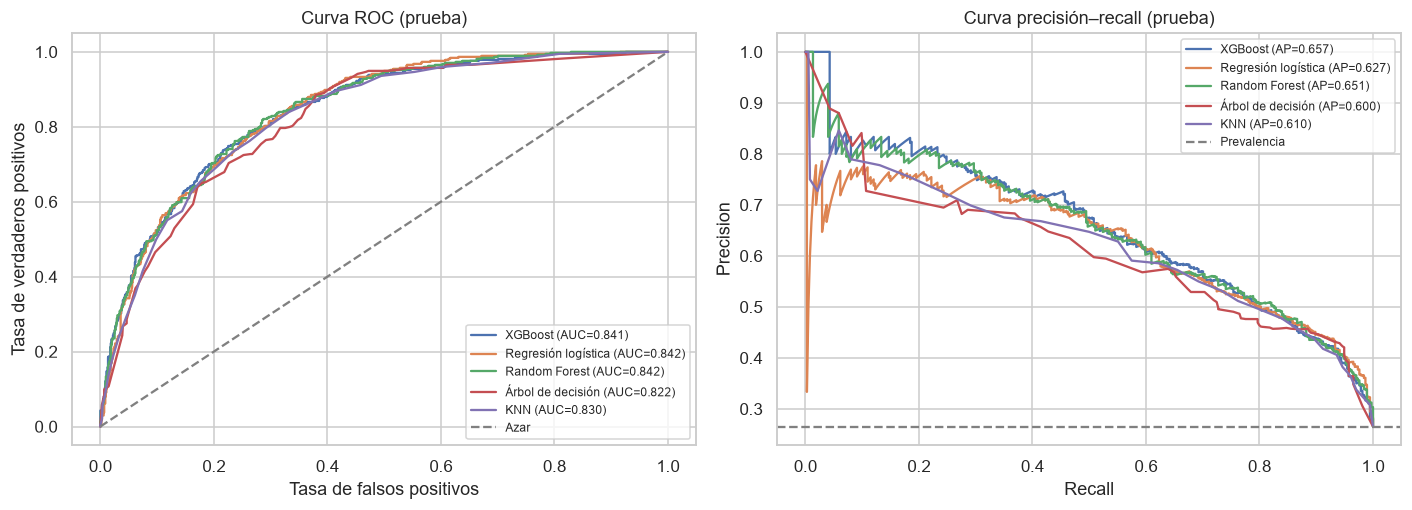

In [18]:
# 13. Curvas ROC y precisión–recall (prueba)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colores = dict(zip(tabla_validacion.index, sns.color_palette("deep", len(tabla_validacion))))

for nombre in tabla_validacion.index:
    probabilidad = probabilidades_test[nombre]
    color = colores[nombre]

    fpr, tpr, _ = roc_curve(y_test, probabilidad)
    axes[0].plot(
        fpr,
        tpr,
        color=color,
        label=f"{nombre} (AUC={roc_auc_score(y_test, probabilidad):.3f})",
    )

    precision, recall, _ = precision_recall_curve(y_test, probabilidad)
    axes[1].plot(
        recall,
        precision,
        color=color,
        label=f"{nombre} (AP={average_precision_score(y_test, probabilidad):.3f})",
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar")
axes[0].set_title("Curva ROC (prueba)")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(fontsize=8)

axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Prevalencia")
axes[1].set_title("Curva precisión–recall (prueba)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.show()

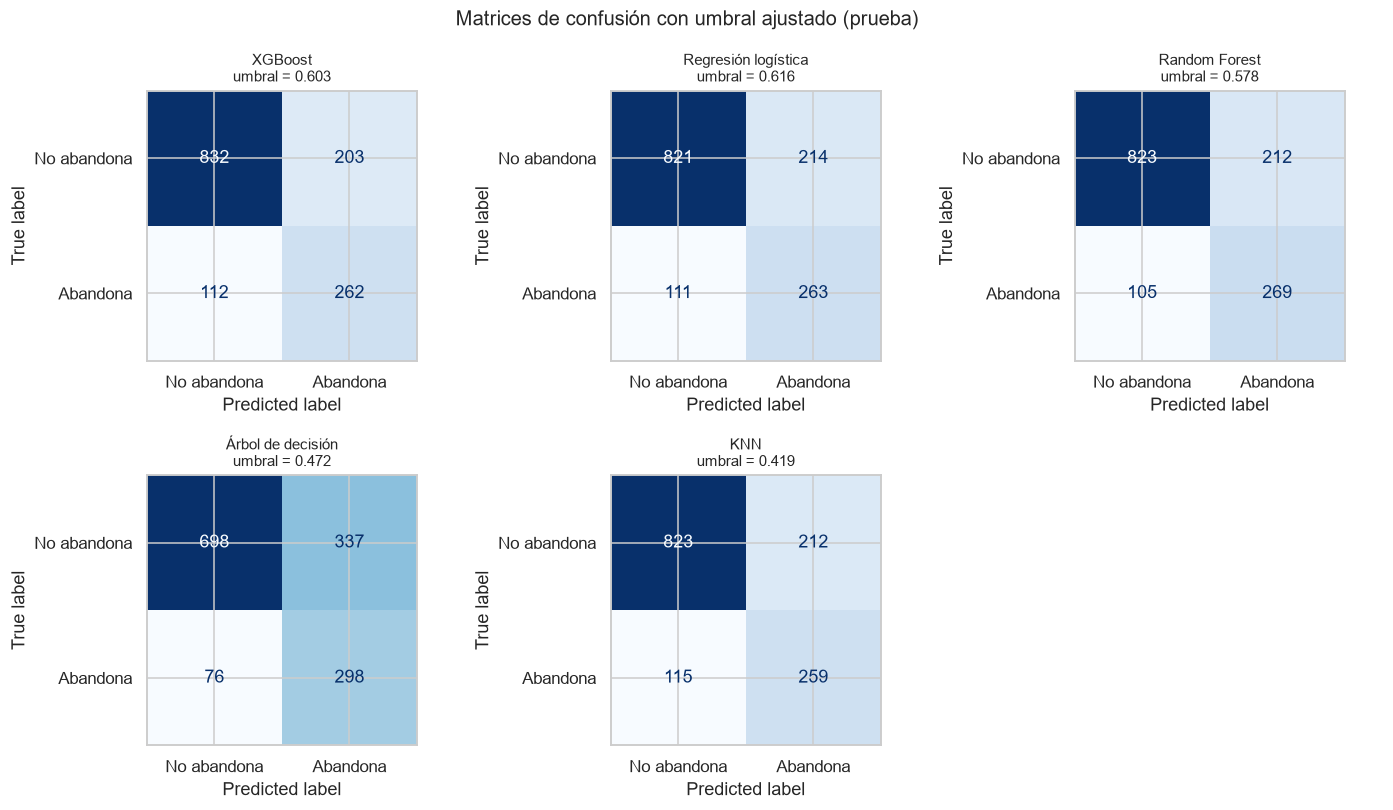

In [19]:
# 14. Matrices de confusión con el umbral ajustado
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))

for ax, nombre in zip(axes.ravel(), tabla_validacion.index):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones_test[nombre],
        display_labels=["No abandona", "Abandona"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{nombre}\numbral = {umbrales[nombre]:.3f}", fontsize=10)

axes.ravel()[-1].axis("off")
fig.suptitle("Matrices de confusión con umbral ajustado (prueba)", fontsize=13)
fig.tight_layout()
plt.show()

Mayor riesgo condicional:
InternetService_Fiber optic   1.162
Contract_Month-to-month       0.722
TotalCharges                  0.612
StreamingTV_Yes               0.499
StreamingMovies_Yes           0.472

Menor riesgo condicional:
MonthlyCharges        -1.581
tenure                -1.271
InternetService_DSL   -0.944
Contract_Two year     -0.899
InternetService_No    -0.460


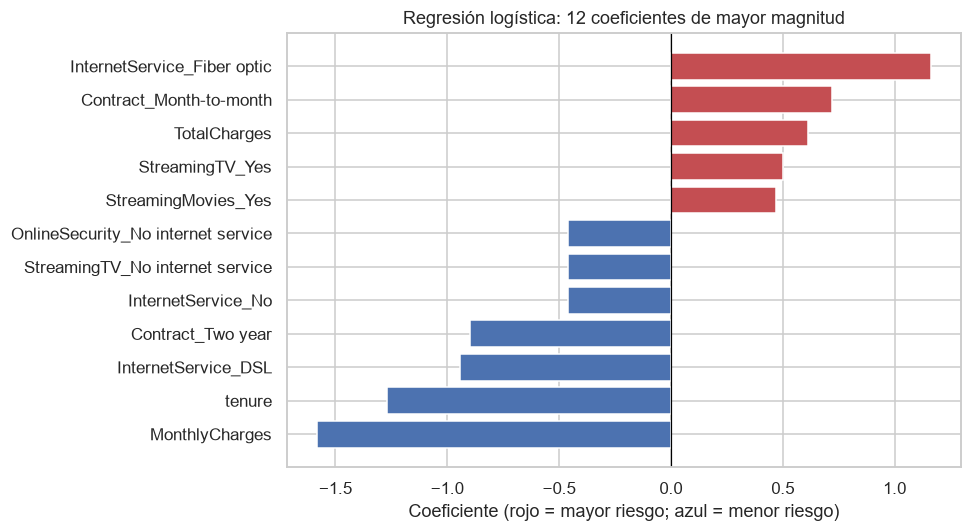

In [20]:
# 15. Interpretación: coeficientes de la regresión logística
# Coeficientes condicionales: tenure, MonthlyCharges y TotalCharges están
# correlacionadas, por lo que un signo puede invertirse al controlar por las demás.
# No deben leerse como efectos causales aislados.
modelo_lr = mejores_modelos["Regresión logística"]
nombres_lr = modelo_lr.named_steps["preprocesador"].get_feature_names_out()
coeficientes = modelo_lr.named_steps["clf"].coef_[0]

serie_lr = (
    pd.Series(coeficientes, index=nombres_lr)
    .rename(lambda nombre: nombre.replace("num_mediana__", "").replace("num_cero__", "").replace("cat__", ""))
    .sort_values(key=np.abs, ascending=False)
    .head(12)
    .sort_values()
)

print("Mayor riesgo condicional:")
print(serie_lr[serie_lr > 0].sort_values(ascending=False).head(5).to_string())
print("\nMenor riesgo condicional:")
print(serie_lr[serie_lr < 0].head(5).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
colores_lr = ["#C44E52" if valor > 0 else "#4C72B0" for valor in serie_lr]
ax.barh(serie_lr.index, serie_lr.values, color=colores_lr)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Regresión logística: 12 coeficientes de mayor magnitud")
ax.set_xlabel("Coeficiente (rojo = mayor riesgo; azul = menor riesgo)")
fig.tight_layout()
plt.show()

Variables más importantes:
Contract_Month-to-month       0.152
tenure                        0.123
TotalCharges                  0.083
Contract_Two year             0.076
OnlineSecurity_No             0.073
TechSupport_No                0.053
MonthlyCharges                0.053
InternetService_Fiber optic   0.049


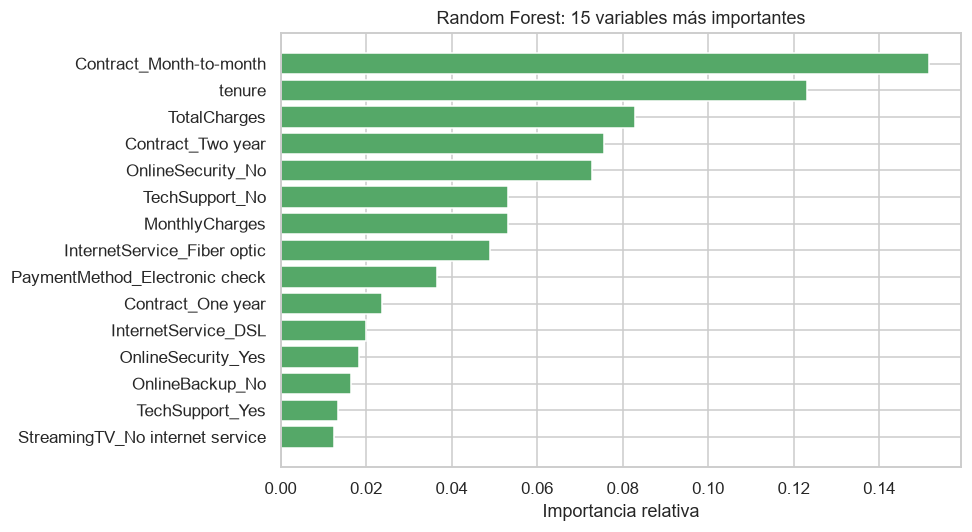

In [21]:
# 16. Interpretación: importancia de variables en Random Forest
modelo_rf = mejores_modelos["Random Forest"]
nombres_rf = modelo_rf.named_steps["preprocesador"].get_feature_names_out()
importancias = (
    pd.Series(
        modelo_rf.named_steps["clf"].feature_importances_,
        index=nombres_rf,
    )
    .rename(lambda nombre: nombre.replace("num_mediana__", "").replace("num_cero__", "").replace("cat__", ""))
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

print("Variables más importantes:")
print(importancias.sort_values(ascending=False).head(8).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importancias.index, importancias.values, color="#55A868")
ax.set_title("Random Forest: 15 variables más importantes")
ax.set_xlabel("Importancia relativa")
fig.tight_layout()
plt.show()

In [22]:
# 17. Resumen: selección en validación y confirmación en prueba
# El modelo se elige por AP de validación; prueba solo confirma su desempeño.
resumen_final = pd.DataFrame(
    {
        "AP validación": tabla_validacion["Average precision"],
        "AP prueba": tabla_prueba["Average precision"],
        "Recall prueba (umbral)": tabla_prueba["Recall (umbral ajustado)"],
        "Precision prueba (umbral)": tabla_prueba["Precision (umbral ajustado)"],
        "F1 prueba (umbral)": tabla_prueba["F1 (umbral ajustado)"],
    }
).reindex(tabla_validacion.index)
resumen_final.insert(0, "Seleccionado", resumen_final.index == modelo_seleccionado)

print(f"Modelo seleccionado en validación: {modelo_seleccionado}")
print(f"  AP validación: {tabla_validacion.loc[modelo_seleccionado, 'Average precision']:.3f}")
print(f"  AP prueba    : {tabla_prueba.loc[modelo_seleccionado, 'Average precision']:.3f}")

resumen_final.round(3)

Modelo seleccionado en validación: XGBoost
  AP validación: 0.648
  AP prueba    : 0.657


,Seleccionado,AP validación,AP prueba,Recall prueba (umbral),Precision prueba (umbral),F1 prueba (umbral)
Modelo,,,,,,
XGBoost,True,0.648,0.657,0.701,0.563,0.625
Regresión logística,False,0.643,0.627,0.703,0.551,0.618
Random Forest,False,0.638,0.651,0.719,0.559,0.629
Árbol de decisión,False,0.601,0.600,0.797,0.469,0.591
KNN,False,0.595,0.610,0.693,0.550,0.613
